# Benchmark retrieval embedding cho hệ thống Legal RAG

Notebook này kiểm tra khả năng tìm kiếm Điều luật liên quan trong pipeline Legal RAG bằng ba mô hình embedding trên cùng dữ liệu `ontology_v4`. Kết quả dùng để chọn baseline retrieval và làm cơ sở cho bước đánh giá hybrid Qdrant + Neo4j + LLM.

## 1. Bài toán và phạm vi benchmark

### Bài toán cần giải quyết

Trong hệ thống Legal RAG, người dùng đặt một câu hỏi pháp luật bằng tiếng Việt. Hệ thống cần tìm ra các Điều luật liên quan nhất để cung cấp bằng chứng cho câu trả lời. Embedding model chuyển câu hỏi và nội dung Điều luật thành vector; Qdrant dùng các vector đó để tìm các Điều luật gần nghĩa nhất.

Câu hỏi nghiên cứu của benchmark là: **trên cùng một tập Điều luật và cùng một bộ câu hỏi, mô hình embedding nào tìm được Điều luật đúng tốt nhất với thời gian truy vấn phù hợp?**

### Phạm vi của thí nghiệm

Benchmark này chỉ đo chất lượng vector retrieval để cô lập ảnh hưởng của embedding model:

```text
Question → Embedding model → Qdrant vector search → Top-k Điều luật → Metrics
```

Neo4j và LLM vẫn thuộc pipeline Legal RAG tổng thể, nhưng không tham gia metric chính trong notebook này. Neo4j sẽ phục vụ mở rộng quan hệ pháp lý; LLM sẽ sinh câu trả lời và citation ở bước đánh giá hybrid riêng.

### Pipeline dữ liệu

```text
ABox TTL ontology v4
        ↓
Projection JSONL
        ↓
chunks.jsonl gồm các Điều luật
        ↓
Mỗi embedding model tạo một collection Qdrant riêng
        ↓
Truy vấn 30 câu hỏi vàng
        ↓
Recall, MRR, nDCG và latency
```

TTL/ABox là nguồn dữ liệu ngữ nghĩa chuẩn. `chunks.jsonl` là projection phục vụ retrieval. Qdrant lưu vector của từng model, còn notebook kiểm tra model nào đưa Điều luật đúng lên vị trí cao hơn và với tốc độ nào.

## 2. Dữ liệu benchmark

Tập dữ liệu gồm các chunk Điều luật được chiếu từ Ontology v4. Bộ câu hỏi vàng được gán nhãn thủ công và dùng chung cho cả ba model, bảo đảm phép so sánh công bằng.

In [1]:
import json
from collections import Counter
from pathlib import Path
import pandas as pd
from IPython.display import display

overview_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / 'labor_rag' / 'evaluation' / 'benchmark_questions.jsonl').exists()
)
overview_questions = [
    json.loads(line)
    for line in (overview_root / 'labor_rag' / 'evaluation' / 'benchmark_questions.jsonl').read_text(encoding='utf-8').splitlines()
    if line.strip()
]
question_category_counts = (
    pd.Series(Counter(str(question.get('category', 'uncategorized')) for question in overview_questions), name='question_count')
    .rename_axis('category')
    .reset_index()
    .sort_values(['question_count', 'category'], ascending=[False, True])
)
display(question_category_counts)
assert int(question_category_counts['question_count'].sum()) == len(overview_questions)
print(f'Tổng số câu hỏi theo nhóm: {int(question_category_counts["question_count"].sum())}')

,category,question_count
5,dieu_kien,7
3,trach_nhiem,7
7,che_do,4
0,quyen_nguoi_lao_dong,3
9,co_quan_tham_quyen,2
8,lao_dong_dac_thu,2
4,dieu_cam,1
6,dinh_nghia,1
10,hieu_luc,1
1,nghia_vu_nguoi_lao_dong,1


Tổng số câu hỏi theo nhóm: 30


### Bộ câu hỏi vàng và nhãn liên quan

Bộ test gồm các câu hỏi thủ công về quyền, nghĩa vụ, điều kiện, trách nhiệm, chế độ, cơ quan có thẩm quyền, điều cấm, định nghĩa, lao động đặc thù và hiệu lực. Mỗi câu hỏi liên kết với một hoặc nhiều `mapc` trong `chunks.jsonl`.

| Điểm relevance | Ý nghĩa |
|---:|---|
| `3` | Điều luật trực tiếp trả lời câu hỏi |
| `2` | Điều luật liên quan mạnh hoặc bổ sung |
| `1` | Điều luật chỉ liên quan yếu |

Gold label được gán thủ công, không dùng LLM để tự tạo nhãn. Vì vậy kết quả phản ánh khả năng truy hồi so với bộ đáp án chuẩn đã định nghĩa trước.

In [2]:
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    path for path in candidates
    if (path / 'labor_rag' / 'evaluation' / 'embedding_benchmark.py').exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from labor_rag.evaluation.embedding_benchmark import (
    DEFAULT_CHUNKS,
    DEFAULT_QUESTIONS,
    DEFAULT_RESULTS,
    MODELS,
    read_jsonl,
)

CHUNKS_PATH = ROOT / 'labor_rag' / 'data' / 'ontology_v4' / 'chunks.jsonl'
QUESTIONS_PATH = ROOT / 'labor_rag' / 'evaluation' / 'benchmark_questions.jsonl'
RESULTS_DIR = ROOT / 'labor_rag' / 'evaluation' / 'results'
SUMMARY_PATH = RESULTS_DIR / 'summary.csv'
PER_QUERY_PATH = RESULTS_DIR / 'per_query_results.jsonl'
print(f'Workspace: {ROOT}')
print(f'Chunks: {CHUNKS_PATH}')
print(f'Results: {RESULTS_DIR}')

C:\Users\MSI\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Workspace: D:\Work\Learn\HK7_2026-2027\PBL6
Chunks: D:\Work\Learn\HK7_2026-2027\PBL6\labor_rag\data\ontology_v4\chunks.jsonl
Results: D:\Work\Learn\HK7_2026-2027\PBL6\labor_rag\evaluation\results


## 3. Mô hình và cấu hình benchmark

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

model_table = pd.DataFrame(MODELS).rename(
    columns={'key': 'key', 'model': 'Hugging Face model', 'collection': 'Qdrant collection'}
)
display(model_table)

chunks = read_jsonl(CHUNKS_PATH)
questions = read_jsonl(QUESTIONS_PATH)
chunk_mapcs = {str(chunk['mapc']) for chunk in chunks}
gold_mapcs = {str(mapc) for question in questions for mapc in question['relevance']}
missing_gold = sorted(gold_mapcs - chunk_mapcs)
validation = pd.DataFrame([{
    'chunk_count': len(chunks),
    'unique_mapc_count': len(chunk_mapcs),
    'question_count': len(questions),
    'gold_mapc_count': len(gold_mapcs),
    'missing_gold_mapc_count': len(missing_gold),
}])
display(validation)
assert len(chunks) == 348, f'Expected 348 chunks, got {len(chunks)}'
assert len(questions) == 30, f'Expected 30 questions, got {len(questions)}'
assert not missing_gold, f'Missing gold MAPC: {missing_gold}'
print('Gold validation: PASS')

,key,Hugging Face model,Qdrant collection
0,bkai,bkai-foundation-models/vietnamese-bi-encoder,legal_v4_bkai
1,bge,BAAI/bge-m3,legal_v4_bge
2,mpnet,sentence-transformers/paraphrase-multilingual-...,legal_v4_mpnet


,chunk_count,unique_mapc_count,question_count,gold_mapc_count,missing_gold_mapc_count
0,348,348,30,42,0


Gold validation: PASS


| Thuộc tính | Giá trị | Ý nghĩa |
|---|---:|---|
| `chunk_count` | 348 | Có 348 chunk Điều luật được đưa vào benchmark. |
| `unique_mapc_count` | 348 | Có 348 mã `mapc` khác nhau; không bị trùng điều luật. |
| `question_count` | 30 | Có 30 câu hỏi vàng được gán nhãn thủ công. |
| `gold_mapc_count` | 42 | Có tổng cộng 42 điều luật được dùng làm đáp án đúng/liên quan. Một câu hỏi có thể có nhiều `mapc`. |
| `missing_gold_mapc_count` | 0 | Không có mã `mapc` nào trong nhãn vàng bị thiếu khỏi dữ liệu chunk. |

## 4. Tạo collection và chạy benchmark

Mỗi model dùng cùng 348 chunk nhưng được lưu trong một collection Qdrant riêng. Quy trình tạo collection là: encode chunk bằng model, chuẩn hóa vector, dùng khoảng cách cosine và lưu payload gồm `mapc`, `uri`, `text`, `citation` cùng metadata nguồn.

Ba collection của thí nghiệm là `legal_v4_bkai`, `legal_v4_bge` và `legal_v4_mpnet`. Collection legacy `labor_dieu` không bị ghi đè. Nếu `index_action = reused`, benchmark phát hiện collection đã có đúng bộ `mapc` và sử dụng lại; điều đó không có nghĩa là collection chưa được tạo.

Thông thường hãy chạy lệnh CLI trước để tải model và tạo hoặc cập nhật ba collection:

```powershell
python -m labor_rag.evaluation.embedding_benchmark --rebuild
```

Nếu muốn chạy trực tiếp từ notebook, đổi `RUN_BENCHMARK` thành `True`. Cấu hình benchmark là `top_k = 10`, warm-up 3 câu hỏi và chạy mỗi câu hỏi 3 lần. Thời gian tải model không được tính vào latency truy vấn; thời gian encode và tìm kiếm Qdrant được đo riêng.

In [4]:
RUN_BENCHMARK = False
if RUN_BENCHMARK:
    from labor_rag.evaluation.embedding_benchmark import run_benchmark
    benchmark_output = run_benchmark(
        chunks_path=CHUNKS_PATH,
        questions_path=QUESTIONS_PATH,
        results_dir=RESULTS_DIR,
        top_k=10,
        warmup=3,
        repeats=3,
        rebuild=False,
    )
    print('Benchmark finished.')
else:
    print('Đang dùng kết quả đã có trong evaluation/results/.')

Đang dùng kết quả đã có trong evaluation/results/.


## 5. Bảng metric tổng hợp

In [5]:
if SUMMARY_PATH.exists():
    summary = pd.read_csv(SUMMARY_PATH)
    per_query = pd.DataFrame(read_jsonl(PER_QUERY_PATH)) if PER_QUERY_PATH.exists() else pd.DataFrame()
    collection_table = summary[['model', 'model_id', 'collection', 'embedding_dimension', 'indexed_points']].copy()
    collection_table.columns = ['Model', 'Hugging Face ID', 'Qdrant collection', 'Dimension', 'Số vector']
    display(collection_table)
    display(summary)
    assert len(summary) == 3, 'Expected exactly three benchmark models'
    assert set(summary['collection']) == {'legal_v4_bkai', 'legal_v4_bge', 'legal_v4_mpnet'}
    assert set(summary['indexed_points']) == {348}
else:
    summary = pd.DataFrame()
    per_query = pd.DataFrame()
    print('Chưa có summary.csv. Hãy chạy CLI hoặc đặt RUN_BENCHMARK=True rồi chạy lại các cell.')

,Model,Hugging Face ID,Qdrant collection,Dimension,Số vector
0,bkai,bkai-foundation-models/vietnamese-bi-encoder,legal_v4_bkai,768,348
1,bge,BAAI/bge-m3,legal_v4_bge,1024,348
2,mpnet,sentence-transformers/paraphrase-multilingual-...,legal_v4_mpnet,768,348


,model,model_id,collection,embedding_dimension,query_count,index_action,indexed_points,Recall@1,Recall@5,Recall@10,MRR@10,nDCG@10,mean_latency_ms,median_latency_ms,mean_encode_latency_ms,mean_search_latency_ms,index_time_seconds
0,bkai,bkai-foundation-models/vietnamese-bi-encoder,legal_v4_bkai,768,30,reused,348,0.933333,0.966667,0.966667,0.941667,0.825000,48.5055,46.2060,37.1783,10.9699,0.0
1,bge,BAAI/bge-m3,legal_v4_bge,1024,30,reused,348,0.833333,0.966667,1.000000,0.889815,0.820115,111.7470,110.3399,96.4823,14.8812,0.0
2,mpnet,sentence-transformers/paraphrase-multilingual-...,legal_v4_mpnet,768,30,reused,348,0.700000,0.833333,0.866667,0.753889,0.623132,45.5190,44.3693,35.8443,9.0161,0.0


### Ý nghĩa các cột kết quả

| Nhóm | Cột | Ý nghĩa |
|---|---|---|
| Model | `model`, `model_id`, `collection` | Model embedding và collection Qdrant tương ứng. |
| Index | `embedding_dimension`, `indexed_points` | Số chiều vector và số vector đã lưu. |
| Index | `index_action`, `index_time_seconds` | Collection được tạo lại hay reuse và thời gian index. |
| Truy hồi | `Recall@1`, `Recall@5`, `Recall@10` | Tỷ lệ câu hỏi có ít nhất một Điều luật đúng trong top-1, top-5 hoặc top-10. |
| Xếp hạng | `MRR@10` | Điều luật đúng đầu tiên đứng càng cao thì điểm càng lớn. |
| Xếp hạng | `nDCG@10` | Chất lượng sắp xếp top-10, có xét relevance `3`, `2`, `1`. |
| Tốc độ | `mean_latency_ms` | Latency trung bình gồm encode câu hỏi và Qdrant search. |
| Tốc độ | `median_latency_ms` | Latency trung vị, ít bị ảnh hưởng bởi lần chạy bất thường. |
| Tốc độ | `mean_encode_latency_ms`, `mean_search_latency_ms` | Thời gian riêng của model và Qdrant. |

Recall trong benchmark này là **hit-rate**: câu hỏi đạt nếu top-k chứa ít nhất một `mapc` thuộc gold relevance. Đây chưa phải độ chính xác của câu trả lời cuối cùng do LLM sinh ra.

In [6]:
if not summary.empty:
    metric_columns = [
        'model', 'embedding_dimension', 'Recall@1', 'Recall@5', 'Recall@10',
        'MRR@10', 'nDCG@10', 'mean_latency_ms', 'median_latency_ms',
        'index_time_seconds',
    ]
    display(summary[metric_columns].style.format({
        'Recall@1': '{:.3f}', 'Recall@5': '{:.3f}', 'Recall@10': '{:.3f}',
        'MRR@10': '{:.3f}', 'nDCG@10': '{:.3f}',
        'mean_latency_ms': '{:.2f}', 'median_latency_ms': '{:.2f}',
        'index_time_seconds': '{:.2f}',
    }))
else:
    print('Chưa có dữ liệu metric để hiển thị.')

,model,embedding_dimension,Recall@1,Recall@5,Recall@10,MRR@10,nDCG@10,mean_latency_ms,median_latency_ms,index_time_seconds
0,bkai,768,0.933,0.967,0.967,0.942,0.825,48.51,46.21,0.00
1,bge,1024,0.833,0.967,1.000,0.890,0.820,111.75,110.34,0.00
2,mpnet,768,0.700,0.833,0.867,0.754,0.623,45.52,44.37,0.00


## 6. Recall@k theo model

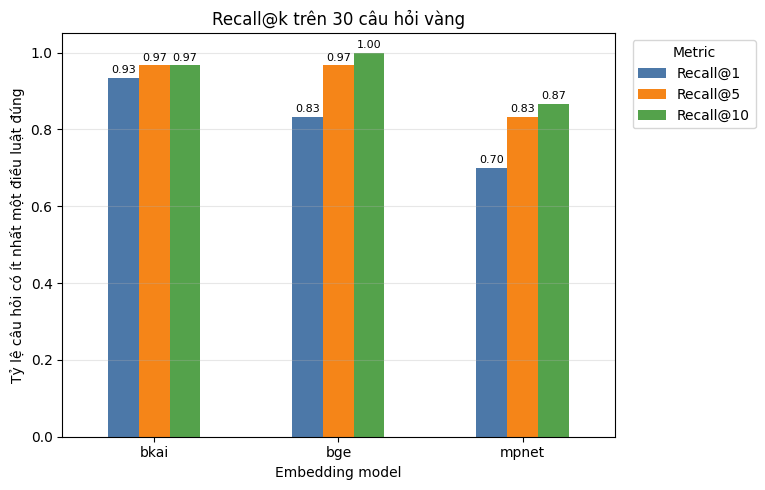

In [7]:
if not summary.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    summary.set_index('model')[['Recall@1', 'Recall@5', 'Recall@10']].plot(
        kind='bar', ax=ax, ylim=(0, 1.05), rot=0,
        color=['#4C78A8', '#F58518', '#54A24B'],
    )
    ax.set_title('Recall@k trên 30 câu hỏi vàng')
    ax.set_ylabel('Tỷ lệ câu hỏi có ít nhất một điều luật đúng')
    ax.set_xlabel('Embedding model')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Metric', loc='upper left', bbox_to_anchor=(1.02, 1.0))
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=2, fontsize=8)
    fig.tight_layout(rect=[0, 0, 0.78, 1])
    plt.show()

### Nhận xét Recall

Recall@k đo tỷ lệ câu hỏi có ít nhất một Điều luật liên quan trong top-k. Điểm cao hơn là tốt hơn. Nhận xét bên dưới được sinh tự động từ `summary.csv`.

In [8]:
if not summary.empty:
    for metric in ['Recall@1', 'Recall@5', 'Recall@10']:
        best_value = summary[metric].max()
        worst_value = summary[metric].min()
        winners = ', '.join(summary.loc[summary[metric] == best_value, 'model'])
        print(f'{metric}: {winners} tốt nhất ({best_value:.3f}); khoảng cách cao nhất-thấp nhất = {best_value - worst_value:.3f}')
    best_top1 = summary.loc[summary['Recall@1'].idxmax(), 'model']
    best_top10 = summary.loc[summary['Recall@10'].idxmax(), 'model']
    print(f'\nDiễn giải: {best_top1} tìm đúng Điều luật ngay ở top-1 tốt nhất; {best_top10} có độ bao phủ top-10 tốt nhất.')
    print('Khi k tăng từ 1 lên 10, Recall tăng vì hệ thống được phép xem nhiều ứng viên hơn.')

Recall@1: bkai tốt nhất (0.933); khoảng cách cao nhất-thấp nhất = 0.233
Recall@5: bkai, bge tốt nhất (0.967); khoảng cách cao nhất-thấp nhất = 0.133
Recall@10: bge tốt nhất (1.000); khoảng cách cao nhất-thấp nhất = 0.133

Diễn giải: bkai tìm đúng Điều luật ngay ở top-1 tốt nhất; bge có độ bao phủ top-10 tốt nhất.
Khi k tăng từ 1 lên 10, Recall tăng vì hệ thống được phép xem nhiều ứng viên hơn.


## 7. MRR và nDCG

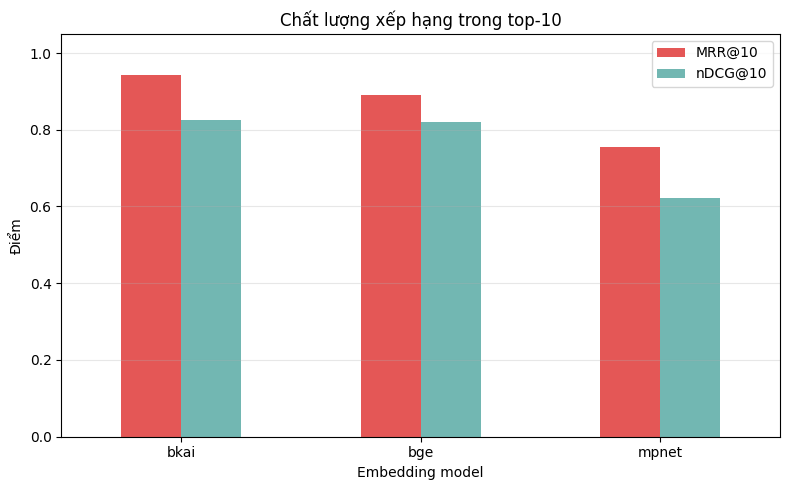

In [9]:
if not summary.empty:
    ax = summary.set_index('model')[['MRR@10', 'nDCG@10']].plot(
        kind='bar', figsize=(8, 5), ylim=(0, 1.05), rot=0,
        color=['#E45756', '#72B7B2'],
    )
    ax.set_title('Chất lượng xếp hạng trong top-10')
    ax.set_ylabel('Điểm')
    ax.set_xlabel('Embedding model')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

### Nhận xét MRR và nDCG

MRR cho biết Điều luật đúng đầu tiên thường đứng ở vị trí nào; nDCG xét thêm mức độ liên quan của nhiều kết quả. Điểm cao hơn nghĩa là thứ tự xếp hạng tốt hơn.

In [10]:
if not summary.empty:
    for metric in ['MRR@10', 'nDCG@10']:
        winner_row = summary.loc[summary[metric].idxmax()]
        print(f'{metric}: {winner_row["model"]} tốt nhất ({winner_row[metric]:.3f}); chênh lệch với model thấp nhất = {winner_row[metric] - summary[metric].min():.3f}')
    print('Diễn giải: model có MRR cao thường đưa Điều luật đúng lên vị trí sớm hơn, giúp giảm số kết quả người dùng phải xem.')

MRR@10: bkai tốt nhất (0.942); chênh lệch với model thấp nhất = 0.188
nDCG@10: bkai tốt nhất (0.825); chênh lệch với model thấp nhất = 0.202
Diễn giải: model có MRR cao thường đưa Điều luật đúng lên vị trí sớm hơn, giúp giảm số kết quả người dùng phải xem.


## 8. Latency truy vấn

encode_latency_ms        search_latency_ms        latency_ms        
                   mean median              mean median       mean  median
model                                                                     
bge               96.48  94.41             14.88   9.61     111.75  110.34
bkai              37.18  35.61             10.97   8.68      48.51   46.21
mpnet             35.84  34.93              9.02   8.19      45.52   44.37

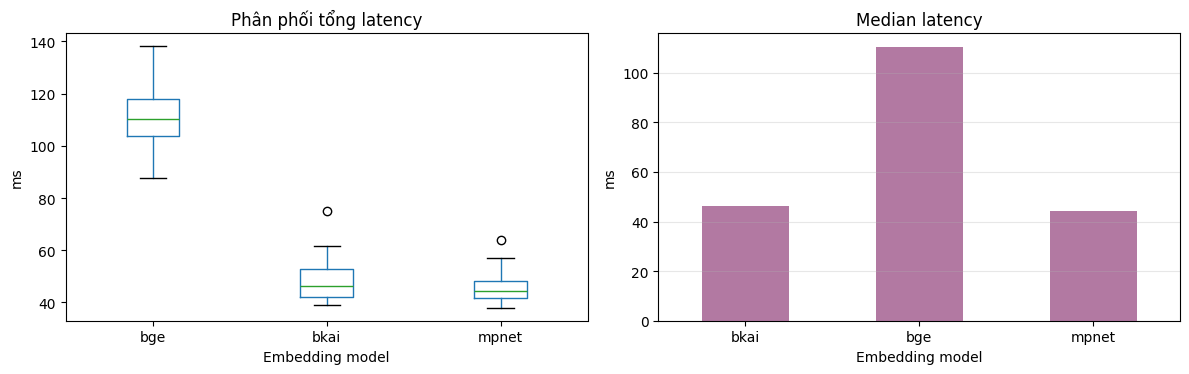

In [11]:
if not per_query.empty:
    latency = per_query[['model', 'question_id', 'latency_ms', 'encode_latency_ms', 'search_latency_ms']].copy()
    display(latency.groupby('model')[['encode_latency_ms', 'search_latency_ms', 'latency_ms']].agg(['mean', 'median']).round(2))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    latency.boxplot(column='latency_ms', by='model', ax=axes[0], grid=False)
    axes[0].set_title('Phân phối tổng latency')
    axes[0].set_xlabel('Embedding model')
    axes[0].set_ylabel('ms')
    summary.set_index('model')['median_latency_ms'].plot(kind='bar', ax=axes[1], rot=0, color='#B279A2')
    axes[1].set_title('Median latency')
    axes[1].set_xlabel('Embedding model')
    axes[1].set_ylabel('ms')
    axes[1].grid(axis='y', alpha=0.3)
    fig.suptitle('')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa có per_query_results.jsonl để vẽ latency.')

### Nhận xét latency

Latency thấp hơn nghĩa là phản hồi nhanh hơn. Cần tách thời gian encode của model và thời gian Qdrant search để biết nút thắt nằm ở đâu.

In [12]:
if not summary.empty:
    fastest = summary.loc[summary['median_latency_ms'].idxmin()]
    slowest = summary.loc[summary['median_latency_ms'].idxmax()]
    print(f'Median latency thấp nhất: {fastest["model"]} ({fastest["median_latency_ms"]:.2f} ms)')
    print(f'Median latency cao nhất: {slowest["model"]} ({slowest["median_latency_ms"]:.2f} ms)')
    if fastest['median_latency_ms'] > 0:
        print(f'{slowest["model"]} chậm khoảng {slowest["median_latency_ms"] / fastest["median_latency_ms"]:.1f} lần so với model nhanh nhất.')
    if (summary['index_action'] == 'reused').all():
        print('Lưu ý: các collection hiện được reuse nên index_time_seconds không dùng để so sánh thời gian xây dựng index trong lần chạy này.')

Median latency thấp nhất: mpnet (44.37 ms)
Median latency cao nhất: bge (110.34 ms)
bge chậm khoảng 2.5 lần so với model nhanh nhất.
Lưu ý: các collection hiện được reuse nên index_time_seconds không dùng để so sánh thời gian xây dựng index trong lần chạy này.


## 9. Heatmap hit top-1 theo từng câu hỏi

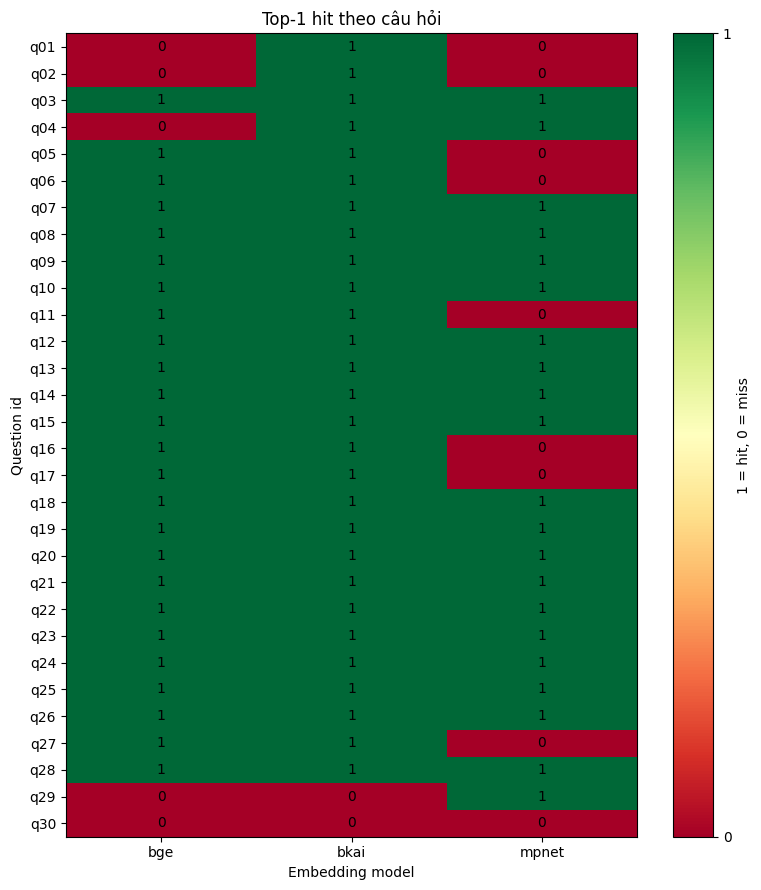

In [13]:
if not per_query.empty:
    top1 = per_query.pivot(index='question_id', columns='model', values='recall_at_1').sort_index()
    fig, ax = plt.subplots(figsize=(8, 9))
    image = ax.imshow(top1.to_numpy(), aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
    ax.set_xticks(range(len(top1.columns)), top1.columns)
    ax.set_yticks(range(len(top1.index)), top1.index)
    ax.set_title('Top-1 hit theo câu hỏi')
    ax.set_xlabel('Embedding model')
    ax.set_ylabel('Question id')
    for row_index in range(top1.shape[0]):
        for col_index in range(top1.shape[1]):
            ax.text(col_index, row_index, int(top1.iloc[row_index, col_index]), ha='center', va='center')
    fig.colorbar(image, ax=ax, ticks=[0, 1], label='1 = hit, 0 = miss')
    plt.tight_layout()
    plt.show()

## 10. Ví dụ top-5 của cùng một câu hỏi

In [14]:
if not per_query.empty:
    example_id = sorted(per_query['question_id'].unique())[0]
    example_question = per_query.loc[per_query['question_id'] == example_id, 'question'].iloc[0]
    display(Markdown(f'**{example_id}:** {example_question}'))
    for model_name, row in per_query[per_query['question_id'] == example_id].groupby('model', sort=False):
        results = row.iloc[0]['top_k_results'][:5]
        table = pd.DataFrame(results)
        display(Markdown(f'### {model_name}'))
        display(table[['rank', 'mapc', 'score', 'citation', 'ten']])

**q01:** Người lao động có những quyền cơ bản nào về an toàn, vệ sinh lao động?

### bkai

,rank,mapc,score,citation,ten
0,1,20.5.LQ.6,0.771862,Điều 20.5.LQ.6,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
1,2,20.5.LQ.7,0.765542,Điều 20.5.LQ.7,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
2,3,20.5.LQ.69,0.603099,Điều 20.5.LQ.69,"An toàn, vệ sinh lao động đối với người lao độ..."
3,4,20.5.LQ.75,0.598820,Điều 20.5.LQ.75,"Hội đồng an toàn, vệ sinh lao động cơ sở"
4,5,20.5.LQ.17,0.594646,Điều 20.5.LQ.17,Trách nhiệm của người lao động trong việc bảo ...


### bge

,rank,mapc,score,citation,ten
0,1,20.5.LQ.7,0.746529,Điều 20.5.LQ.7,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
1,2,20.5.LQ.6,0.738639,Điều 20.5.LQ.6,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
2,3,20.5.LQ.5,0.707939,Điều 20.5.LQ.5,"Nguyên tắc bảo đảm an toàn, vệ sinh lao động"
3,4,20.5.LQ.9,0.695884,Điều 20.5.LQ.9,"Quyền, trách nhiệm của tổ chức công đoàn trong..."
4,5,20.5.LQ.74,0.693797,Điều 20.5.LQ.74,"An toàn, vệ sinh viên"


### mpnet

,rank,mapc,score,citation,ten
0,1,20.5.LQ.7,0.796431,Điều 20.5.LQ.7,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
1,2,20.5.LQ.6,0.784979,Điều 20.5.LQ.6,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
2,3,20.5.LQ.5,0.782458,Điều 20.5.LQ.5,"Nguyên tắc bảo đảm an toàn, vệ sinh lao động"
3,4,20.5.LQ.68,0.778459,Điều 20.5.LQ.68,"An toàn, vệ sinh lao động đối với lao động là ..."
4,5,20.5.LQ.10,0.768045,Điều 20.5.LQ.10,"Quyền, trách nhiệm của công đoàn cơ sở trong c..."


## 11. Kết luận cuối cùng

Phần này tổng hợp kết quả từ `summary.csv`, không hard-code model thắng. Điểm cao hơn là tốt hơn với Recall/MRR/nDCG; latency thấp hơn là tốt hơn. Kết luận chỉ nói về vector retrieval, chưa phải chất lượng câu trả lời cuối của LLM.

In [15]:
if not summary.empty:
    higher_is_better = ['Recall@1', 'Recall@5', 'Recall@10', 'MRR@10', 'nDCG@10']

    def format_metric(metric, value):
        return f'{value:.1%}' if metric.startswith('Recall') else f'{value:.3f}'

    def winner_label(metric):
        best_value = summary[metric].max()
        winners = summary.loc[summary[metric] == best_value, 'model']
        return ', '.join(f'`{model}`' for model in winners), best_value

    lines = [
        '### Kết quả chính',
        '',
        '| Tiêu chí | Model tốt nhất | Giá trị |',
        '|---|---|---:|',
    ]
    for metric in higher_is_better:
        winner_names, best_value = winner_label(metric)
        lines.append(f'| `{metric}` | {winner_names} | {format_metric(metric, best_value)} |')
    fastest_row = summary.loc[summary['median_latency_ms'].idxmin()]
    lines.append(f'| `Median latency` | `{fastest_row["model"]}` | {fastest_row["median_latency_ms"]:.2f} ms |')

    top1_row = summary.loc[summary['Recall@1'].idxmax()]
    top10_row = summary.loc[summary['Recall@10'].idxmax()]
    mrr_row = summary.loc[summary['MRR@10'].idxmax()]
    ndcg_row = summary.loc[summary['nDCG@10'].idxmax()]
    slowest_row = summary.loc[summary['median_latency_ms'].idxmax()]
    quality_winner = summary.loc[summary['MRR@10'].idxmax()]

    lines.extend([
        '',
        '### Diễn giải kết quả',
        f'- `{top1_row["model"]}` tốt nhất ở Recall@1 ({top1_row["Recall@1"]:.1%}), phù hợp khi cần đưa Điều luật đúng lên kết quả đầu tiên.',
        f'- `{top10_row["model"]}` tốt nhất ở Recall@10 ({top10_row["Recall@10"]:.1%}), phù hợp khi ưu tiên độ bao phủ trong top-10.',
        f'- `{mrr_row["model"]}` có MRR@10 cao nhất ({mrr_row["MRR@10"]:.3f}) và `{ndcg_row["model"]}` có nDCG@10 cao nhất ({ndcg_row["nDCG@10"]:.3f}), phản ánh chất lượng xếp hạng.',
        f'- `{fastest_row["model"]}` nhanh nhất với median latency {fastest_row["median_latency_ms"]:.2f} ms; `{slowest_row["model"]}` chậm nhất với {slowest_row["median_latency_ms"]:.2f} ms.',
    ])
    if quality_winner['model'] != slowest_row['model']:
        lines.append(f'- `{quality_winner["model"]}` là lựa chọn baseline cân bằng hiện tại vì đứng đầu MRR@10 nhưng không phải model chậm nhất.')
    if len(set(summary.loc[summary[higher_is_better].idxmax().values, 'model'])) > 1:
        lines.append('- Không có model thắng tuyệt đối: kết quả phụ thuộc vào việc ưu tiên vị trí đầu, độ bao phủ top-10 hay tốc độ.')

    lines.extend([
        '',
        '### Giới hạn của kết luận',
        '- Benchmark chỉ có 348 Điều luật và 30 câu hỏi vàng trong miền an toàn, vệ sinh lao động.',
        '- Chưa fine-tune model, chưa đánh giá Neo4j graph expansion và chưa đánh giá chất lượng câu trả lời cuối của LLM.',
        '- Latency phụ thuộc môi trường Docker, phần cứng và trạng thái cache.',
    ])
    if (summary['index_action'] == 'reused').all():
        lines.append('- Các collection hiện được reuse nên index_time_seconds = 0; chưa dùng kết quả này để so sánh thời gian xây dựng index.')

    lines.extend([
        '',
        '### Hướng phát triển',
        '1. Mở rộng bộ câu hỏi và corpus pháp luật.',
        '2. Đánh giá riêng theo từng nhóm câu hỏi.',
        '3. Tạo benchmark hybrid Qdrant + Neo4j.',
        '4. Đánh giá citation và câu trả lời LLM trước khi chọn model triển khai chính.',
    ])
    display(Markdown('\n'.join(lines)))
else:
    print('Chưa có kết quả để kết luận.')

### Kết quả chính

| Tiêu chí | Model tốt nhất | Giá trị |
|---|---|---:|
| `Recall@1` | `bkai` | 93.3% |
| `Recall@5` | `bkai`, `bge` | 96.7% |
| `Recall@10` | `bge` | 100.0% |
| `MRR@10` | `bkai` | 0.942 |
| `nDCG@10` | `bkai` | 0.825 |
| `Median latency` | `mpnet` | 44.37 ms |

### Diễn giải kết quả
- `bkai` tốt nhất ở Recall@1 (93.3%), phù hợp khi cần đưa Điều luật đúng lên kết quả đầu tiên.
- `bge` tốt nhất ở Recall@10 (100.0%), phù hợp khi ưu tiên độ bao phủ trong top-10.
- `bkai` có MRR@10 cao nhất (0.942) và `bkai` có nDCG@10 cao nhất (0.825), phản ánh chất lượng xếp hạng.
- `mpnet` nhanh nhất với median latency 44.37 ms; `bge` chậm nhất với 110.34 ms.
- `bkai` là lựa chọn baseline cân bằng hiện tại vì đứng đầu MRR@10 nhưng không phải model chậm nhất.
- Không có model thắng tuyệt đối: kết quả phụ thuộc vào việc ưu tiên vị trí đầu, độ bao phủ top-10 hay tốc độ.

### Giới hạn của kết luận
- Benchmark chỉ có 348 Điều luật và 30 câu hỏi vàng trong miền an toàn, vệ sinh lao động.
- Chưa fine-tune model, chưa đánh giá Neo4j graph expansion và chưa đánh giá chất lượng câu trả lời cuối của LLM.
- Latency phụ thuộc môi trường Docker, phần cứng và trạng thái cache.
- Các collection hiện được reuse nên index_time_seconds = 0; chưa dùng kết quả này để so sánh thời gian xây dựng index.

### Hướng phát triển
1. Mở rộng bộ câu hỏi và corpus pháp luật.
2. Đánh giá riêng theo từng nhóm câu hỏi.
3. Tạo benchmark hybrid Qdrant + Neo4j.
4. Đánh giá citation và câu trả lời LLM trước khi chọn model triển khai chính.